# Glioma survival analysis — Step 4: tree-based survival models

Why trees after Cox?
* Cox assumes **linear** effects on the log-hazard and **proportional hazards**. Step 3 showed `age` and `chr7_10` still violate PH.
* Tree ensembles learn non-linear effects and interactions (e.g. age matters differently in IDHwt vs IDHmut) with no PH assumption.

Models (scikit-survival):
* **Random Survival Forest (RSF)** — bagged survival trees, log-rank splitting, prediction = averaged Nelson-Aalen curve.
* **Gradient Boosting Survival (GBSA)** — boosted regression trees optimizing the Cox partial likelihood.

**Nested CV:** the *outer* loop is exactly the same 15 folds as Step 3 (same seed), so results are directly comparable
fold-by-fold with Cox. Inside each outer fold, `GridSearchCV` (3-fold) picks hyperparameters using only that fold's training part.

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sksurv.ensemble import RandomSurvivalForest, GradientBoostingSurvivalAnalysis
from sksurv.linear_model import CoxPHSurvivalAnalysis

from survival_utils import (load_data, split, make_preprocessor, cross_validate, evaluate,
                            summarize, survival_at, SEED)

X, y = load_data("../data/processed/glioma.csv")
X_train, X_test, y_train, y_test = split(X, y)
print(len(X_train), len(X_test))

832 208


## 1. Hyperparameter grids
Kept small on purpose: ~830 patients is not much, and big grids mostly fit noise in the inner CV.
Inner-CV score = Harrell's C (the estimators' default `.score`).

In [2]:
def tuned(model, grid):
    pipe = Pipeline([("pre", make_preprocessor()), ("model", model)])
    grid = {f"model__{k}": v for k, v in grid.items()}
    return GridSearchCV(pipe, grid, cv=3, n_jobs=-1)

models = {
    "RSF": tuned(
        RandomSurvivalForest(n_estimators=300, random_state=SEED),
        {"min_samples_leaf": [5, 15, 30], "max_features": ["sqrt", 0.5]},
    ),
    "GBSA": tuned(
        GradientBoostingSurvivalAnalysis(subsample=0.8, random_state=SEED),
        {"learning_rate": [0.05, 0.1], "n_estimators": [100, 300], "max_depth": [2, 3]},
    ),
}

## 2. Nested cross-validation

In [3]:
%%time
cv4 = {name: cross_validate(m, X_train, y_train) for name, m in models.items()}

CPU times: user 12.7 s, sys: 394 ms, total: 13.1 s
Wall time: 47 s


In [4]:
cv3 = pd.read_csv("../results/cv_step3.csv")
cv_all = {n: g.drop(columns="model").reset_index(drop=True) for n, g in cv3.groupby("model", sort=False)}
cv_all.update(cv4)

pd.concat([r.assign(model=n) for n, r in cv4.items()]).to_csv("../results/cv_step4.csv", index=False)

cols = ["harrell_c", "uno_c", "auc_6m", "auc_12m", "auc_24m", "auc_36m", "mean_auc", "ibs"]
summarize(cv_all)[cols]

,harrell_c,uno_c,auc_6m,auc_12m,auc_24m,auc_36m,mean_auc,ibs
KM baseline,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.218 ± 0.011
Cox – age,0.735 ± 0.03,0.725 ± 0.029,0.794 ± 0.051,0.773 ± 0.055,0.8 ± 0.05,0.823 ± 0.038,0.796 ± 0.037,0.166 ± 0.013
Cox – clinical,0.789 ± 0.027,0.788 ± 0.025,0.831 ± 0.041,0.818 ± 0.043,0.858 ± 0.041,0.901 ± 0.026,0.852 ± 0.029,0.139 ± 0.014
Cox – molecular,0.775 ± 0.027,0.778 ± 0.024,0.797 ± 0.046,0.811 ± 0.046,0.861 ± 0.048,0.89 ± 0.042,0.841 ± 0.033,0.139 ± 0.014
Cox – full,0.793 ± 0.027,0.795 ± 0.026,0.825 ± 0.04,0.824 ± 0.039,0.872 ± 0.044,0.914 ± 0.03,0.859 ± 0.031,0.134 ± 0.015
"Cox – full, strat.",0.786 ± 0.024,0.783 ± 0.024,0.832 ± 0.037,0.815 ± 0.037,0.855 ± 0.042,0.899 ± 0.028,0.849 ± 0.028,0.133 ± 0.016
RSF,0.787 ± 0.031,0.79 ± 0.029,0.819 ± 0.049,0.821 ± 0.047,0.864 ± 0.045,0.903 ± 0.037,0.853 ± 0.036,0.137 ± 0.015
GBSA,0.785 ± 0.025,0.789 ± 0.024,0.818 ± 0.044,0.82 ± 0.042,0.865 ± 0.039,0.907 ± 0.034,0.853 ± 0.029,0.139 ± 0.015


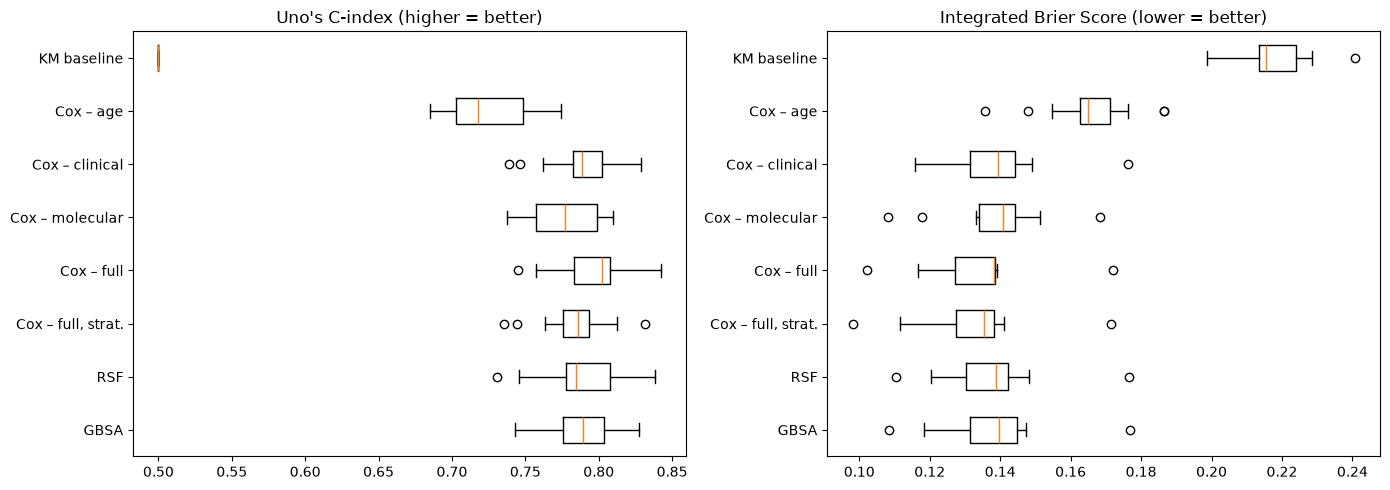

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
names = list(cv_all)
for a, metric, title in [(ax[0], "uno_c", "Uno's C-index (higher = better)"),
                         (ax[1], "ibs", "Integrated Brier Score (lower = better)")]:
    a.boxplot([cv_all[n][metric] for n in names], vert=False, tick_labels=names)
    a.set_title(title); a.invert_yaxis()
plt.tight_layout()

### Paired comparison against Cox – full
Same folds → we can look at the per-fold *difference*. This removes the fold-to-fold noise
(some folds are just harder for every model), so it is much more sensitive than comparing the boxplots.

In [6]:
cox = cv_all["Cox – full"]
rows = []
for name in cv4:
    for metric, better in [("uno_c", 1), ("mean_auc", 1), ("ibs", -1)]:
        d = cv4[name][metric].to_numpy() - cox[metric].to_numpy()
        rows.append({"model": name, "metric": metric, "mean diff vs Cox": d.mean(),
                     "std": d.std(ddof=1), "folds where better": f"{(better * d > 0).sum()}/{len(d)}"})
pd.DataFrame(rows).round(4)

,model,metric,mean diff vs Cox,std,folds where better
0,RSF,uno_c,-0.0052,0.0105,4/15
1,RSF,mean_auc,-0.0065,0.0104,3/15
2,RSF,ibs,0.0035,0.0039,3/15
3,GBSA,uno_c,-0.0063,0.0074,4/15
4,GBSA,mean_auc,-0.0061,0.0091,4/15
5,GBSA,ibs,0.0048,0.0028,1/15


### Which hyperparameters did the inner CV pick?
If the choice jumps around between folds, the grid is flat → the exact values do not matter much.

In [7]:
for name, r in cv4.items():
    print(name)
    print(r["params"].value_counts().to_string(), "\n")

RSF
params
{'model__max_features': 'sqrt', 'model__min_samples_leaf': 5}     10
{'model__max_features': 0.5, 'model__min_samples_leaf': 15}        3
{'model__max_features': 'sqrt', 'model__min_samples_leaf': 15}     2 

GBSA
params
{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}     9
{'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 300}    5
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}     1 



### Sanity check: was the grid too narrow?
In the nested CV the inner search often picked the **edge** of the grid (RSF `min_samples_leaf=5`, GBSA `max_depth=2`).
That can mean the optimum lies outside it, so here the grids are widened (GBSA `max_depth=1` = an additive model with no interactions).

In [8]:
%%time
wide = {
    "RSF wide": tuned(RandomSurvivalForest(n_estimators=300, random_state=SEED),
                      {"min_samples_leaf": [3, 5, 10, 20], "max_features": ["sqrt", 0.3]}),
    "GBSA wide": tuned(GradientBoostingSurvivalAnalysis(subsample=0.8, random_state=SEED),
                       {"learning_rate": [0.03, 0.1], "n_estimators": [50, 100, 300], "max_depth": [1, 2]}),
}
for name, m in wide.items():
    r = cross_validate(m, X_train, y_train)
    print(name, r[["uno_c", "mean_auc", "ibs"]].mean().round(4).to_dict())
    print(r["params"].value_counts().head(3).to_string(), "\n")

RSF wide {'uno_c': 0.7923, 'mean_auc': 0.8553, 'ibs': 0.1364}
params
{'model__max_features': 'sqrt', 'model__min_samples_leaf': 10}    11
{'model__max_features': 'sqrt', 'model__min_samples_leaf': 5}      4 



GBSA wide {'uno_c': 0.789, 'mean_auc': 0.8515, 'ibs': 0.1388}
params
{'model__learning_rate': 0.1, 'model__max_depth': 1, 'model__n_estimators': 300}     10
{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}      2
{'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 300}     2 

CPU times: user 17.4 s, sys: 644 ms, total: 18 s
Wall time: 1min 5s


## 3. Final models on the hold-out test set
Tune on the whole training set (5-fold inner CV), evaluate once on test. Cox – full refit for reference.

In [9]:
final = {}
for name, m in models.items():
    m.set_params(cv=5)
    final[name] = m.fit(X_train, y_train)
    print(name, final[name].best_params_)

final["Cox – full"] = Pipeline([("pre", make_preprocessor()), ("model", CoxPHSurvivalAnalysis(alpha=0.1))]).fit(X_train, y_train)

test4 = pd.DataFrame({n: evaluate(m, y_train, X_test, y_test) for n, m in final.items()}).T.round(3)
test4.to_csv("../results/test_step4.csv")
test4

RSF {'model__max_features': 'sqrt', 'model__min_samples_leaf': 15}


GBSA {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}


,harrell_c,uno_c,auc_6m,auc_12m,auc_24m,auc_36m,mean_auc,ibs
RSF,0.810,0.811,0.835,0.841,0.914,0.909,0.874,0.120
GBSA,0.804,0.805,0.831,0.847,0.908,0.899,0.871,0.125
Cox – full,0.812,0.813,0.833,0.848,0.916,0.909,0.877,0.118


## 4. Do the trees find non-linear effects? — partial dependence of age
For each age value we set **every** training patient's age to that value, predict S(24 months), and average.
Cox is forced to a smooth logistic-like shape; trees can bend wherever the data says so.
Shown separately for IDHwt and IDH-mutant patients to see an interaction.

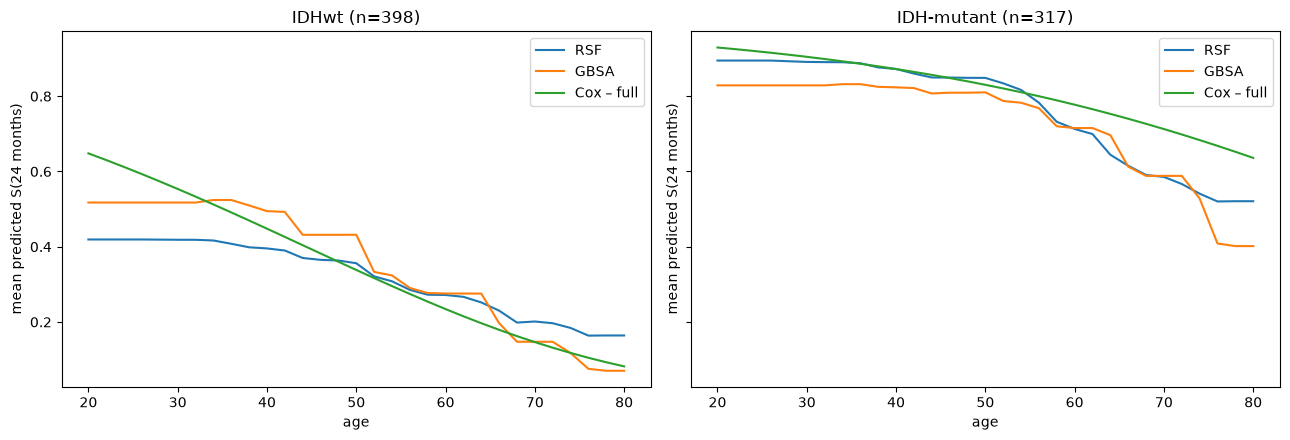

In [10]:
ages = np.arange(20, 81, 2)
groups = {"IDHwt": X_train["subtype"] == "IDHwt",
          "IDH-mutant": X_train["subtype"].isin(["IDHmut-codel", "IDHmut-non-codel"])}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (gname, mask) in zip(axes, groups.items()):
    base = X_train[mask]
    for name, m in final.items():
        pd_curve = [survival_at(m, base.assign(age=a), np.array([24]))[:, 0].mean() for a in ages]
        ax.plot(ages, pd_curve, label=name)
    ax.set(title=f"{gname} (n={mask.sum()})", xlabel="age", ylabel="mean predicted S(24 months)")
    ax.legend()
plt.tight_layout()

## Summary

**Nested CV (same 15 folds as Step 3):**

| model | Uno's C | mean AUC | IBS |
|---|---|---|---|
| Cox – full | **0.795 ± 0.026** | **0.859** | **0.134** |
| RSF | 0.790 ± 0.029 | 0.853 | 0.137 |
| GBSA | 0.789 ± 0.024 | 0.853 | 0.139 |
| RSF / GBSA, wider grids | 0.792 / 0.789 | 0.855 / 0.852 | 0.136 / 0.139 |

**Hold-out test:** Cox 0.813 / IBS 0.118 · RSF 0.811 / 0.120 · GBSA 0.805 / 0.125.

Takeaways
* **The tree models do not beat Cox.** In the paired comparison Cox wins in 11–14 of 15 folds; the gap is small
  (~0.005 C-index) but consistent. A wider grid does not change this.
* GBSA's inner CV prefers `max_depth=1`, i.e. **no interactions**. Together with the result above, this says the
  signal in these 7 features is mostly additive and roughly linear, which is Cox's home turf.
  With ~830 patients and few features, the trees' extra flexibility costs more variance than it gains.
* Partial dependence: in IDH-mutant patients both trees show a sharper drop in 24-month survival after ~55 years
  than Cox's smooth curve (a possible threshold effect). At the extremes (<35, >75) the trees go flat,
  which is the usual tree behaviour where data is sparse, not necessarily biology.
* The PH violations from Step 3 therefore hurt **interpretation** of the HRs more than **prediction**.

**Implication for Step 5 (DeepSurv):** on tabular data this small, a neural net is unlikely to win either.
Its value would be as a methodological comparison, or later as the head that takes **imaging features** (UNET/radiomics).